# Project P706 – By Group 2

**P. Rishitha Reddy**

**Kottu Karthik**

**Palthi Sathwik**

**Rakshita Basavaraj Dooganavar**

**Rampalli Rupak Teja**

**M. P. Chandrasekharan Nair**


# 🌍 Cluster Analysis – Global Development Measurement
## Project Overview

Countries differ significantly in their economic performance, social conditions, health outcomes, demographic structure, business environment, and overall standard of living. However, countries with very different geographical locations may exhibit similar development characteristics.

This project aims to use **unsupervised machine learning and clustering techniques** to identify groups of countries that share similar development profiles based on a range of global development indicators.

Rather than analysing countries individually, clustering allows us to discover **natural patterns and segments within the data** without using predefined labels.

## Business Objective

The primary objective is to **segment countries into meaningful clusters based on their development characteristics**.

The analysis will consider indicators such as:

* Economic factors – GDP, lending interest, business tax, etc.
* Health indicators – health expenditure, infant mortality, life expectancy
* Demographic indicators – birth rate, population distribution, total population
* Infrastructure & technology – energy usage, internet usage, mobile phone usage
* Business environment – ease of business, days to start a business, tax compliance
* Environmental and tourism indicators – CO₂ emissions, inbound and outbound tourism

The resulting clusters will be analysed and profiled to understand the characteristics of different groups of countries.

## Project Approach

The project will progress through the following stages:

**1. Business & Dataset Understanding**
Understand the business problem, dataset structure, variables, and expected outcome.

**2. Data Cleaning & Exploratory Data Analysis (EDA)**
Assess data quality, handle missing values and inconsistencies, identify outliers, examine distributions and relationships, and derive meaningful insights from the data.

**3. Feature Preparation & Model Building**
Select relevant features, scale the data, apply different clustering algorithms, and determine appropriate cluster configurations.

**4. Comparative Model Analysis**
Compare the clustering approaches using suitable clustering evaluation metrics and interpret the resulting clusters.

**5. Deployment**
Develop an interactive application using **Streamlit/Flask** to assign and visualize country clusters and explore their characteristics.

**6. Final Presentation**
Present the methodology, EDA findings, clustering results, model comparison, cluster profiles, and deployed application.

### Project Goal

> **To transform global development indicators into meaningful country segments using clustering and convert the resulting analytical insights into an interactive application.**


# 📅 Project Roadmap & Milestones

The project will be completed in approximately **30 days**, following the agreed milestones.

| Milestone                                         | Duration | Target      |
| ------------------------------------------------- | -------: | ----------- |
| Kick-off, Business Objective & Dataset Discussion |    1 Day | 16-Sep-2026 |
| Exploratory Data Analysis & Data Preparation      |   1 Week | 23-Sep-2026 |
| Model Building & Clustering                       |   1 Week | 30-Sep-2026 |
| Deployment                                        |   1 Week | 07-Oct-2026 |
| Final Presentation                                |   1 Week | 14-Oct-2026 |

### Current Milestone – EDA

The current phase focuses on understanding the dataset, improving data quality, preparing the features, and extracting meaningful insights through exploratory analysis.

**Expected outcome of this phase:**
A clean, validated, and analysis-ready dataset suitable for clustering.


In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
import re
from sklearn.preprocessing import StandardScaler


import warnings
warnings.filterwarnings('ignore')



ModuleNotFoundError: No module named 'pandas'

In [ ]:
import pandas as pd

gdf = pd.read_excel(
    r"C:\Users\yashwanth\Downloads\Clustering - global development\P706_ World_development_mesurement.xlsx",
    engine="openpyxl"
)

print(gdf.shape)
print(gdf.head())

(2704, 25)
   Birth Rate Business Tax Rate  CO2 Emissions       Country  \
0       0.020               NaN        87931.0       Algeria   
1       0.050               NaN         9542.0        Angola   
2       0.043               NaN         1617.0         Benin   
3       0.027               NaN         4276.0      Botswana   
4       0.046               NaN         1041.0  Burkina Faso   

   Days to Start Business  Ease of Business  Energy Usage              GDP  \
0                     NaN               NaN       26998.0  $54,790,058,957   
1                     NaN               NaN        7499.0   $9,129,594,819   
2                     NaN               NaN        1983.0   $2,359,122,303   
3                     NaN               NaN        1836.0   $5,788,311,645   
4                     NaN               NaN           NaN   $2,610,959,139   

   Health Exp % GDP Health Exp/Capita  ...  Life Expectancy Male  \
0             0.035               $60  ...                  67.0   

In [ ]:
gdf.sample(10)

,Birth Rate,Business Tax Rate,CO2 Emissions,Country,Days to Start Business,Ease of Business,Energy Usage,GDP,Health Exp % GDP,Health Exp/Capita,...,Life Expectancy Male,Mobile Phone Usage,Number of Records,Population 0-14,Population 15-64,Population 65+,Population Total,Population Urban,Tourism Inbound,Tourism Outbound
460,0.041,NaN,NaN,South Sudan,NaN,NaN,NaN,NaN,NaN,NaN,...,49.0,NaN,1,0.445,0.524,0.031,7186820,0.168,NaN,NaN
2147,0.014,NaN,71624.0,"Korea, Dem. Rep.",NaN,NaN,18794.0,NaN,NaN,NaN,...,66.0,0.0,1,0.227,0.686,0.088,24500520,0.602,NaN,NaN
2068,NaN,NaN,NaN,Sint Maarten (Dutch part),NaN,NaN,NaN,NaN,NaN,NaN,...,73.0,NaN,1,NaN,NaN,NaN,39133,1.000,"$619,000,000","$104,000,000"
88,0.011,NaN,524.0,Andorra,NaN,NaN,NaN,"$1,133,644,295",0.062,"$1,330",...,NaN,0.4,1,NaN,NaN,NaN,65399,0.924,NaN,NaN
1781,NaN,NaN,NaN,Monaco,NaN,NaN,NaN,"$6,919,241,412",0.036,"$6,623",...,NaN,0.6,1,NaN,NaN,NaN,35686,1.000,NaN,NaN
2136,0.021,35.0%,56153.0,Bangladesh,19.0,NaN,30756.0,"$100,360,101,354",0.037,$24,...,69.0,0.4,1,0.317,0.637,0.046,151125475,0.305,"$103,000,000","$835,000,000"
2281,0.018,27.9%,2384.0,Suriname,694.0,NaN,NaN,"$4,368,033,802",0.058,$483,...,67.0,1.0,1,0.286,0.649,0.064,524960,0.663,"$69,000,000","$41,000,000"
107,NaN,NaN,NaN,Isle of Man,NaN,NaN,NaN,"$1,563,667,800",NaN,NaN,...,NaN,NaN,1,NaN,NaN,NaN,76806,0.518,NaN,NaN
914,0.013,NaN,252345.0,Thailand,33.0,NaN,96291.0,"$161,339,790,595",0.035,$87,...,69.0,0.4,1,0.228,0.697,0.075,65087400,0.363,"$13,054,000,000","$5,343,000,000"
421,0.043,NaN,220.0,Burundi,NaN,NaN,NaN,"$825,394,484",0.071,$6,...,48.0,0.0,1,0.476,0.495,0.028,7037727,0.087,"$1,600,000","$14,000,000"


In [ ]:
gdf.shape

(2704, 25)

In [ ]:
gdf.info()

<class 'pandas.DataFrame'>
RangeIndex: 2704 entries, 0 to 2703
Data columns (total 25 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Birth Rate              2585 non-null   float64
 1   Business Tax Rate       1423 non-null   str    
 2   CO2 Emissions           2125 non-null   float64
 3   Country                 2704 non-null   str    
 4   Days to Start Business  1718 non-null   float64
 5   Ease of Business        185 non-null    float64
 6   Energy Usage            1785 non-null   float64
 7   GDP                     2494 non-null   str    
 8   Health Exp % GDP        2395 non-null   float64
 9   Health Exp/Capita       2395 non-null   str    
 10  Hours to do Tax         1416 non-null   float64
 11  Infant Mortality Rate   2444 non-null   float64
 12  Internet Usage          2531 non-null   float64
 13  Lending Interest        1880 non-null   float64
 14  Life Expectancy Female  2568 non-null   float64
 15

### Column names and description

1. Birth Rate – Number of births per 1,000 people in the population.

2. Business Tax Rate – Tax rate applicable to businesses, generally expressed as a percentage.

3. CO2 Emissions – Amount of carbon dioxide emissions produced by the country, usually measured in metric tonnes.

4. Country – Name of the country; serves as the country identifier.

5. Days to Start Business – Number of days required to legally start a business.

6. Ease of Business – Indicator showing how easy or difficult it is to start and operate a business in a country.

7. Energy Usage – Amount of energy consumed or used by the country.

8. GDP – Gross Domestic Product; the total value of goods and services produced by a country's economy.

9. Health Exp % GDP – Health expenditure expressed as a percentage of the country's GDP.

10. Health Exp/Capita – Health expenditure per person (per capita).

11. Hours to do Tax – Number of hours businesses typically spend complying with tax-related requirements.

12. Infant Mortality Rate – Number of infant deaths per 1,000 live births.

13. Internet Usage – Percentage or proportion of the population using the Internet.

14. Lending Interest – Interest rate charged by financial institutions when lending money.

15. Life Expectancy Female – Average number of years a female is expected to live.

16. Life Expectancy Male – Average number of years a male is expected to live.

17. Mobile Phone Usage – Level or percentage of mobile-phone usage in the country.

18. Number of Records – Number of records represented by the row; likely a data-source or record-count field.

19. Population 0-14 – Percentage or proportion of the population aged 0–14 years.

20. Population 15-64 – Percentage or proportion of the population aged 15–64 years.

21. Population 65+ – Percentage or proportion of the population aged 65 years and above.

22. Population Total – Total population of the country.

23. Population Urban – Percentage or proportion of the population living in urban areas.

24. Tourism Inbound – Tourism coming into the country; represents international visitors arriving in the country.

25. Tourism Outbound – Tourism going out of the country; represents residents travelling to other countries.


### Unique Value Analysis

As part of the initial data inspection, the **number of unique values in each column** will be examined to understand the nature and variability of the variables.

This analysis will help identify **categorical variables, country identifiers, constant or low-variation columns, and variables that may require special treatment** before proceeding with data cleaning, exploratory analysis, and clustering.


In [ ]:
for col in gdf.columns:
    print(f"{col}: {gdf[col].nunique()} unique values")

Birth Rate: 47 unique values
Business Tax Rate: 447 unique values
CO2 Emissions: 1743 unique values
Country: 208 unique values
Days to Start Business: 126 unique values
Ease of Business: 185 unique values
Energy Usage: 1721 unique values
GDP: 2494 unique values
Health Exp % GDP: 145 unique values
Health Exp/Capita: 1069 unique values
Hours to do Tax: 280 unique values
Infant Mortality Rate: 129 unique values
Internet Usage: 11 unique values
Lending Interest: 351 unique values
Life Expectancy Female: 49 unique values
Life Expectancy Male: 47 unique values
Mobile Phone Usage: 26 unique values
Number of Records: 1 unique values
Population 0-14: 376 unique values
Population 15-64: 298 unique values
Population 65+: 208 unique values
Population Total: 2699 unique values
Population Urban: 822 unique values
Tourism Inbound: 1650 unique values
Tourism Outbound: 1457 unique values


### Interpretation of Unique Value Analysis

The unique-value analysis provides an initial understanding of the variability and nature of the variables.

Most development indicators contain a reasonable number of distinct values and can therefore be considered for further exploratory analysis. The `Country` column contains 208 unique values and will be retained as an identifier for country-level interpretation and cluster profiling, but it will not be used directly as a numerical feature for clustering.

The `Internet Usage` and `Mobile Phone Usage` variables contain relatively fewer unique values compared with the other numerical indicators. This may be due to the way these indicators have been recorded or rounded. Their actual values and data types will therefore be examined during the data-quality assessment before making any decision about their suitability.

The `Number of Records` column contains only one unique value and therefore has no variation across observations. Since a constant variable cannot contribute to distinguishing between clusters, it is considered redundant and will be removed.

**Action:** The `Number of Records` column will be dropped, while the remaining variables will be retained for further data-quality assessment and exploratory analysis.


In [ ]:
gdf['Number of Records'].unique()

array([1])

In [ ]:
#drop Number of Records
gdf.drop('Number of Records', axis=1, inplace=True)

In [ ]:
gdf.shape

(2704, 24)

## Data Quality Assessment

**Duplicates**

In [ ]:
duplicate_count = gdf.duplicated().sum()

print("Number of duplicate records:", duplicate_count)

Number of duplicate records: 0


### Data Type and Missing Value Assessment – Procedure

The duplicate-record check confirms that **no duplicate records are present** in the dataset.

The descriptive statistics also indicate the presence of missing values in most of the variables, with the exception of the three variables having complete observations.

Before proceeding with missing-value treatment, the **data type of each variable** and the **number and percentage of missing values** will be examined. Particular attention will be given to columns stored as `object` even though they are numerical in nature. Such columns, if identified, will be converted to the appropriate numerical data type before deciding on the appropriate method for handling missing values.


**Missing values**

In [ ]:
dtype_missing_summary = pd.DataFrame({
    'Data Type': gdf.dtypes,
    'Missing Count': gdf.isnull().sum(),
    'Missing %': (gdf.isnull().mean() * 100).round(2)
})

dtype_missing_summary[dtype_missing_summary['Missing Count'] > 0].sort_values(
    'Missing %', ascending=False
)

,Data Type,Missing Count,Missing %
Ease of Business,float64,2519,93.16
Hours to do Tax,float64,1288,47.63
Business Tax Rate,str,1281,47.37
Days to Start Business,float64,986,36.46
Energy Usage,float64,919,33.99
Lending Interest,float64,824,30.47
CO2 Emissions,float64,579,21.41
Tourism Outbound,str,471,17.42
Tourism Inbound,str,368,13.61
Health Exp/Capita,str,309,11.43


**Checking for all object columns**

In [ ]:
object_cols = gdf.select_dtypes(include='object').columns

print("Object columns:")
print(object_cols.tolist())

Object columns:
['Business Tax Rate', 'Country', 'GDP', 'Health Exp/Capita', 'Tourism Inbound', 'Tourism Outbound']


### Interpretation

The data-type assessment identifies six `object` columns: **Business Tax Rate, Country, GDP, Health Exp/Capita, Tourism Inbound, and Tourism Outbound**.

The **Country** column is categorical and serves as the country identifier; it has no missing values and will not be considered a numerical feature for clustering.

The remaining five `object` columns are numerical development indicators and contain missing values. These columns will therefore be examined further to determine whether they are numerical values stored as text and will be converted to appropriate numerical data types before missing-value treatment.


## Identification of Non-Numeric Characters

The five numerical development indicators are currently stored as object data types. One possible reason is the presence of non-numeric characters within their values. While digits and a decimal point (.) are valid in numerical values, other characters such as commas, percentage signs, currency symbols, spaces, or alphabetic characters may cause numerical values to be stored as text. Therefore, the values will be examined for such characters before converting the columns to appropriate numerical data types.

In [ ]:
num_object_cols = [
    'Business Tax Rate',
    'GDP',
    'Health Exp/Capita',
    'Tourism Inbound',
    'Tourism Outbound'
]

for col in num_object_cols:
    # Convert values to string and find characters
    # other than digits and decimal point
    non_numeric_chars = (
        gdf[col]
        .dropna()
        .astype(str)
        .str.findall(r'[^0-9.]')
        .explode()
        .dropna()
        .value_counts()
    )

    print(f"\n{col}:")
    #print(non_numeric_chars)
    print(non_numeric_chars.to_string())


Business Tax Rate:
Business Tax Rate
%    1423

GDP:
GDP
,    7335
$    2494

Health Exp/Capita:
Health Exp/Capita
$    2395
,     463

Tourism Inbound:
Tourism Inbound
,    5685
$    2336

Tourism Outbound:
Tourism Outbound
,    5266
$    2233


### Purpose of the Code

The code:

- Takes each **non-missing value** from the column.
- Treats each value as **text**.
- Identifies characters other than **digits (`0–9`) and decimal point (`.`)**.
- Separates the identified characters.
- Removes empty or missing results.
- Counts the **frequency of each non-numeric character** present in the column.

The analysis identifies the following non-numeric characters in the numerical variables stored as `object`:

- **Business Tax Rate:** `%`
- **GDP:** `,` and `$`
- **Health Exp/Capita:** `$` and `,`
- **Tourism Inbound:** `,` and `$`
- **Tourism Outbound:** `,` and `$`

These characters are formatting symbols present within the numerical values and are responsible for these columns being stored as `object` data types. Therefore, they need to be removed before converting the columns to appropriate numerical data types.

### Purification of Numerical Object Columns

The numerical object columns contain formatting characters that need to be removed before converting them into appropriate numerical data types. The purification is carried out in two steps:

1. **Business Tax Rate:** Remove the `%` character.
2. **GDP, Health Exp/Capita, Tourism Inbound, and Tourism Outbound:** Remove the `$` and `,` characters.

### **The purified values are then converted to the `float` data type.**


In [ ]:
# Remove formatting characters and convert numerical object columns to numeric

gdf['Business Tax Rate'] = (
    gdf['Business Tax Rate']
    .str.replace('%', '', regex=False)
    .str.strip()
    .astype(float)
)

for col in ['GDP', 'Health Exp/Capita', 'Tourism Inbound', 'Tourism Outbound']:
    gdf[col] = (
        gdf[col]
        .str.replace('$', '', regex=False)
        .str.replace(',', '', regex=False)
        .str.strip()
        .astype(float)
    )

**Check the data types**

In [ ]:
gdf[['Business Tax Rate',
     'GDP',
     'Health Exp/Capita',
     'Tourism Inbound',
     'Tourism Outbound']].dtypes

Business Tax Rate    float64
GDP                  float64
Health Exp/Capita    float64
Tourism Inbound      float64
Tourism Outbound     float64
dtype: object

**Check the actual values**

In [ ]:
gdf[['Business Tax Rate',
     'GDP',
     'Health Exp/Capita',
     'Tourism Inbound',
     'Tourism Outbound']].sample(10)

,Business Tax Rate,GDP,Health Exp/Capita,Tourism Inbound,Tourism Outbound
2458,80.0,2.394854e+10,115.0,4.990000e+08,4.100000e+08
1704,46.6,9.672120e+08,289.0,4.600000e+07,7.000000e+06
1145,26.4,1.628633e+10,5329.0,6.350000e+08,9.910000e+08
533,NaN,2.905973e+09,2985.0,NaN,NaN
1732,32.5,1.002216e+12,1253.0,1.347900e+10,2.145600e+10
1173,57.3,8.614202e+10,117.0,3.542000e+09,3.078000e+09
1116,32.5,8.130259e+09,19.0,1.600000e+08,2.210000e+08
520,NaN,6.638949e+10,495.0,3.774000e+09,2.211000e+09
1883,65.9,9.593537e+09,54.0,NaN,NaN
628,NaN,4.205691e+09,19.0,3.800000e+07,5.000000e+07


## Missing Values

In [ ]:
dtype_missing_summary = pd.DataFrame({
    'Data Type': gdf.dtypes,
    'Missing Count': gdf.isnull().sum(),
    'Missing %': (gdf.isnull().mean() * 100).round(2)
})

dtype_missing_summary[dtype_missing_summary['Missing Count'] > 0].sort_values(
    'Missing %', ascending=False
)

,Data Type,Missing Count,Missing %
Ease of Business,float64,2519,93.16
Hours to do Tax,float64,1288,47.63
Business Tax Rate,float64,1281,47.37
Days to Start Business,float64,986,36.46
Energy Usage,float64,919,33.99
Lending Interest,float64,824,30.47
CO2 Emissions,float64,579,21.41
Tourism Outbound,float64,471,17.42
Tourism Inbound,float64,368,13.61
Health Exp/Capita,float64,309,11.43


### Strategy for Handling Missing Values

The missing-value analysis shows considerable variation in the percentage of missing observations across the numerical variables. Therefore, the missing-value treatment will be based on the **extent of missingness**, while also considering the potential impact of imputation on the clustering results.

Variables with **very high missing percentages** will be excluded from further analysis, as imputing a large proportion of their values may introduce substantial artificial information and distort the underlying cluster structure.

Accordingly, the following variables will be dropped:

* **Ease of Business** – 93.16%
* **Hours to do Tax** – 47.63%
* **Business Tax Rate** – 47.37%
* **Days to Start Business** – 36.46%
* **Energy Usage** – 33.99%
* **Lending Interest** – 30.47%

The remaining numerical variables have comparatively lower levels of missingness and will be retained. Their missing values will be **imputed using the median**, which is less sensitive to extreme values and is therefore suitable for development indicators that may have skewed distributions.

After imputation, the dataset will be checked again to ensure that **no missing values remain** before proceeding to outlier analysis and further exploratory data analysis.


### Drop columns with high missingness

In [ ]:
gdf.shape

(2704, 24)

In [ ]:
# Drop columns with high percentage of missing values

cols_to_drop = [
    'Ease of Business',
    'Hours to do Tax',
    'Business Tax Rate',
    'Days to Start Business',
    'Energy Usage',
    'Lending Interest'
]

gdf.drop(columns=cols_to_drop, inplace=True)

In [ ]:
gdf.shape

(2704, 18)

### imputation using the median

In [ ]:
median_impute_cols = [
    'CO2 Emissions',
    'Tourism Outbound',
    'Tourism Inbound',
    'Health Exp/Capita',
    'Health Exp % GDP',
    'Infant Mortality Rate',
    'Population 65+',
    'Population 15-64',
    'Population 0-14',
    'GDP',
    'Internet Usage',
    'Mobile Phone Usage',
    'Life Expectancy Male',
    'Life Expectancy Female',
    'Birth Rate',
    'Population Urban'
]

In [ ]:
# Impute missing values with the median

gdf[median_impute_cols] = gdf[median_impute_cols].fillna(
    gdf[median_impute_cols].median()
)

In [ ]:
gdf.isnull().sum()

Birth Rate                0
CO2 Emissions             0
Country                   0
GDP                       0
Health Exp % GDP          0
Health Exp/Capita         0
Infant Mortality Rate     0
Internet Usage            0
Life Expectancy Female    0
Life Expectancy Male      0
Mobile Phone Usage        0
Population 0-14           0
Population 15-64          0
Population 65+            0
Population Total          0
Population Urban          0
Tourism Inbound           0
Tourism Outbound          0
dtype: int64

In [ ]:
gdf.isnull().sum().sum()

np.int64(0)

### Check the dataset after cleaning

In [ ]:
print(f"Shape: {gdf.shape}\n")

print("Info:")
gdf.info()

print("\nDescribe:")
print(gdf.describe().T)

Shape: (2704, 18)

Info:
<class 'pandas.DataFrame'>
RangeIndex: 2704 entries, 0 to 2703
Data columns (total 18 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Birth Rate              2704 non-null   float64
 1   CO2 Emissions           2704 non-null   float64
 2   Country                 2704 non-null   str    
 3   GDP                     2704 non-null   float64
 4   Health Exp % GDP        2704 non-null   float64
 5   Health Exp/Capita       2704 non-null   float64
 6   Infant Mortality Rate   2704 non-null   float64
 7   Internet Usage          2704 non-null   float64
 8   Life Expectancy Female  2704 non-null   float64
 9   Life Expectancy Male    2704 non-null   float64
 10  Mobile Phone Usage      2704 non-null   float64
 11  Population 0-14         2704 non-null   float64
 12  Population 15-64        2704 non-null   float64
 13  Population 65+          2704 non-null   float64
 14  Population Total        27

## Interpretation and Next Steps

The data-cleaning process is now complete. Six variables with high percentages of missing values were removed, while the remaining missing values were imputed using the median. The final dataset contains **2,704 observations and 18 columns with no missing values**. The descriptive statistics also indicate considerable variation and skewness in several development indicators, particularly GDP, CO₂ emissions, population, and tourism.

Since this is an **unsupervised clustering problem**, there is no target variable to analyse. The next stage is therefore **Exploratory Data Analysis (EDA)** to understand the distributions, outliers, and relationships among the development indicators.

### Next Steps

1. **Univariate EDA** – examine distributions and boxplots to identify skewness and potential outliers.
2. **Bivariate/Multivariate EDA** – examine relationships among development indicators using correlation analysis and a correlation heatmap. This will help identify highly correlated or redundant features.
3. **EDA Findings** – summarize the important patterns and observations.
4. **Clustering Readiness** – finalize the features and scale them before applying clustering algorithms.

The dataset will then be ready for **K-Means, Hierarchical Clustering, and DBSCAN/other suitable clustering methods**.


### Note on Variable Classification

The variables in the dataset are classified into **categorical** and **numerical variables** based on their nature and the type of information they represent, rather than solely on their pandas data type.

* **Categorical variables** represent names, labels, or groups and are used to identify or classify observations. In this dataset, `Country` is a categorical variable and serves as the country identifier.

* **Numerical variables** represent measurable or quantifiable values such as population, tourism, emissions, expenditure, and life expectancy. These variables are used for numerical analysis and statistical exploration.

This classification is used to determine the appropriate **exploratory data analysis (EDA) techniques and visualization methods**. Categorical variables are primarily examined using frequency-based visualizations, while numerical variables are analyzed using distribution plots such as histograms and box plots.


In [ ]:
categorical_cols = gdf.select_dtypes(include='object').columns.tolist()

numerical_cols = gdf.select_dtypes(include='number').columns.tolist()

print("Categorical Columns:", categorical_cols)
print("Numerical Columns:", numerical_cols)
print("Total Columns:", len(categorical_cols) + len(numerical_cols))

Categorical Columns: ['Country']
Numerical Columns: ['Birth Rate', 'CO2 Emissions', 'GDP', 'Health Exp % GDP', 'Health Exp/Capita', 'Infant Mortality Rate', 'Internet Usage', 'Life Expectancy Female', 'Life Expectancy Male', 'Mobile Phone Usage', 'Population 0-14', 'Population 15-64', 'Population 65+', 'Population Total', 'Population Urban', 'Tourism Inbound', 'Tourism Outbound']
Total Columns: 18


### Categorical Variables
Country is a categorical identifier with 208 unique values. Since each country represents an individual observation and the variable primarily serves as an identifier, its standalone frequency distribution is not particularly informative. Therefore, rather than visualizing all country categories, Country is used as a reference variable for interpreting numerical distributions, comparisons, and clustering results.

### Numerical Variables Analysis

The dataset contains **17 numerical variables** representing demographic, economic, health, environmental, technological, population, and tourism-related indicators.

At this stage of the EDA, these numerical variables will be examined to understand their **distribution, central tendency, spread, variability, and presence of potential outliers**. Appropriate statistical summaries and visualizations will be used to identify the characteristics and patterns of each variable.

The analysis will primarily include:

* **Descriptive statistics** to understand the central tendency and spread of the variables.
* **Distribution analysis** using histograms to examine the shape, skewness, and range of the data.
* **Outlier analysis** using box plots to identify unusually high or low observations.
* **Comparison of scales and magnitudes** across variables to understand the need for subsequent preprocessing and scaling before applying clustering algorithms.

These observations will help guide the **data preprocessing, feature selection, and scaling steps** required for the subsequent clustering analysis.


### **Descriptive statistics** to understand the central tendency and spread of the variables.

In [ ]:
gdf[numerical_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
Birth Rate,2704.0,2.259541e-02,1.110001e-02,7.000000e-03,1.300000e-02,2.000000e-02,3.000000e-02,5.300000e-02
CO2 Emissions,2704.0,1.136616e+05,5.487421e+05,7.000000e+00,2.237000e+03,8.529000e+03,4.256200e+04,8.286892e+06
GDP,2704.0,2.445336e+11,1.087172e+12,6.310127e+07,4.113748e+09,1.507975e+10,9.101825e+10,1.624460e+13
Health Exp % GDP,2704.0,6.380732e-02,2.479479e-02,8.000000e-03,4.800000e-02,6.100000e-02,7.600000e-02,2.250000e-01
Health Exp/Capita,2704.0,7.318724e+02,1.400121e+03,2.000000e+00,5.800000e+01,1.930000e+02,5.512500e+02,9.908000e+03
Infant Mortality Rate,2704.0,3.158099e-02,2.873929e-02,2.000000e-03,1.000000e-02,2.000000e-02,4.900000e-02,1.410000e-01
Internet Usage,2704.0,2.308062e-01,2.539833e-01,0.000000e+00,0.000000e+00,1.000000e-01,4.000000e-01,1.000000e+00
Life Expectancy Female,2704.0,7.135244e+01,1.046911e+01,3.900000e+01,6.500000e+01,7.500000e+01,7.900000e+01,8.700000e+01
Life Expectancy Male,2704.0,6.658950e+01,9.167741e+00,3.700000e+01,6.100000e+01,6.900000e+01,7.300000e+01,8.800000e+01
Mobile Phone Usage,2704.0,5.732988e-01,4.601356e-01,0.000000e+00,2.000000e-01,5.000000e-01,9.000000e-01,2.900000e+00


### Interpretation of Descriptive Statistics

The numerical variables show substantial variation in scale and dispersion across countries. Variables such as GDP, Population Total, CO₂ Emissions, and Tourism have very large ranges and means considerably higher than their medians, indicating strong right-skewness and potential outliers. Several proportion/rate variables also show considerable variability.

**Since clustering is distance-based, these differences in scale and skewness can disproportionately influence cluster formation. Therefore, the next EDA steps should focus on distribution/skewness and outlier analysis, followed by appropriate transformation and feature scaling before applying clustering algorithms.**

### **Distribution analysis using histograms** to examine the shape, skewness, and range of the data.

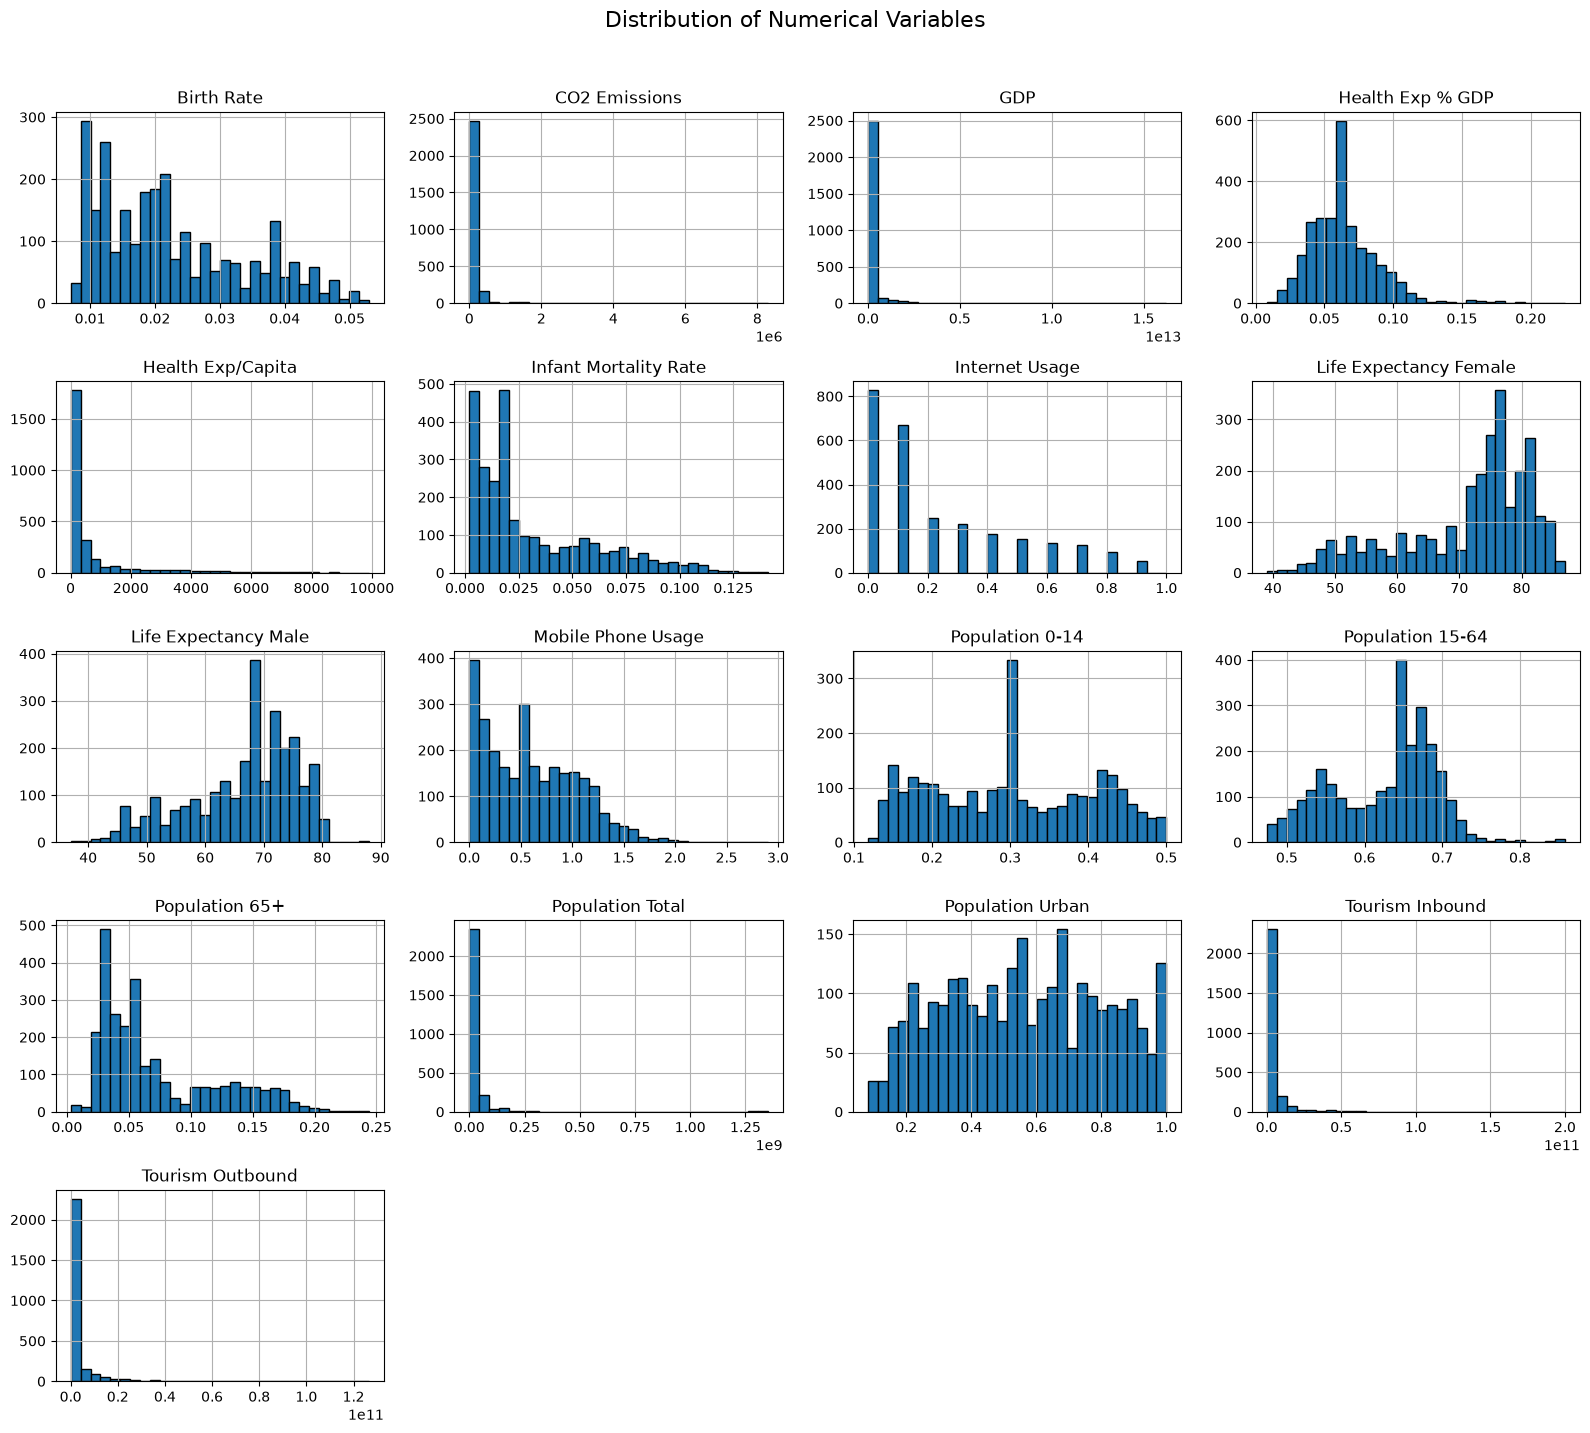

In [ ]:
gdf[numerical_cols].hist(
    figsize=(16, 14),
    bins=30,
    edgecolor='black'
)

plt.suptitle(
    'Distribution of Numerical Variables',
    fontsize=16,
    y=1.02
)

plt.tight_layout()
plt.show()

### Interpretation of Distribution Analysis

The histograms reveal substantial differences in the distributions of the development indicators. **GDP, Population Total, CO₂ Emissions, Tourism Inbound, Tourism Outbound, and Health Exp/Capita are strongly right-skewed**, indicating the presence of observations with exceptionally high values. Other variables show moderate skewness or multi-modal/structured distributions, particularly the demographic and life-expectancy indicators.

From a clustering perspective, these findings are important because **extreme values and differences in scale can disproportionately influence distance-based clustering algorithms** such as K-Means. However, skewness or a non-normal distribution alone is not a reason to remove a variable, since such patterns may represent genuine differences between countries.

### Next Procedure – Preparing for Clustering

The distribution analysis will be followed by:

1. **Skewness analysis** – quantify the degree of skewness in each numerical variable.
2. **Outlier analysis using boxplots** – identify extreme observations and determine whether they are genuine values or potential data issues.
3. **Correlation analysis** – identify strongly related or potentially redundant features, particularly among population, life-expectancy, GDP, tourism, and demographic indicators.
4. **Feature transformation** – apply suitable transformations, such as `log1p()`, to strongly right-skewed variables where appropriate.
5. **Recheck distributions** – verify the effect of transformations on skewness and extreme values.
6. **Final feature selection** – retain meaningful, non-redundant indicators for clustering.
7. **Feature scaling** – standardize the final features so that variables with different units and magnitudes contribute comparably to distance calculations.

The resulting standardized feature set will then be used for **K-Means, Hierarchical Clustering, and DBSCAN/other suitable clustering methods**, followed by model evaluation and cluster profiling.

### Skewness Analysis

In [ ]:
skewness = gdf[numerical_cols].skew().sort_values(ascending=False)

print("Skewness of Numerical Variables:")
print(skewness)

Skewness of Numerical Variables:
GDP                       9.809793
CO2 Emissions             9.768254
Population Total          8.788164
Tourism Inbound           7.638561
Tourism Outbound          5.757210
Health Exp/Capita         3.047889
Health Exp % GDP          1.293975
Infant Mortality Rate     1.195218
Internet Usage            1.041279
Population 65+            1.040362
Birth Rate                0.706320
Mobile Phone Usage        0.617739
Population 0-14           0.070722
Population Urban          0.012928
Population 15-64         -0.260727
Life Expectancy Male     -0.760670
Life Expectancy Female   -0.958938
dtype: float64


### Interpretation of Skewness Analysis

The skewness analysis shows that GDP, CO₂ Emissions, Population Total, Tourism Inbound, Tourism Outbound, and Health Exp/Capita are highly right-skewed. These variables may cause extreme observations to have disproportionate influence on distance-based clustering.

Health Exp % GDP, Infant Mortality Rate, Internet Usage, and Population 65+ show moderate to strong skewness and require further examination. The remaining variables show relatively low to moderate skewness and do not indicate an immediate need for transformation.

**Therefore, the highly skewed variables will be investigated for suitable transformation, such as log1p(),** while variables with lower skewness will generally be retained in their existing form. Boxplot-based outlier analysis and correlation analysis will be performed before finalizing the transformation and feature set for clustering.

### Outlier analysis using boxplots




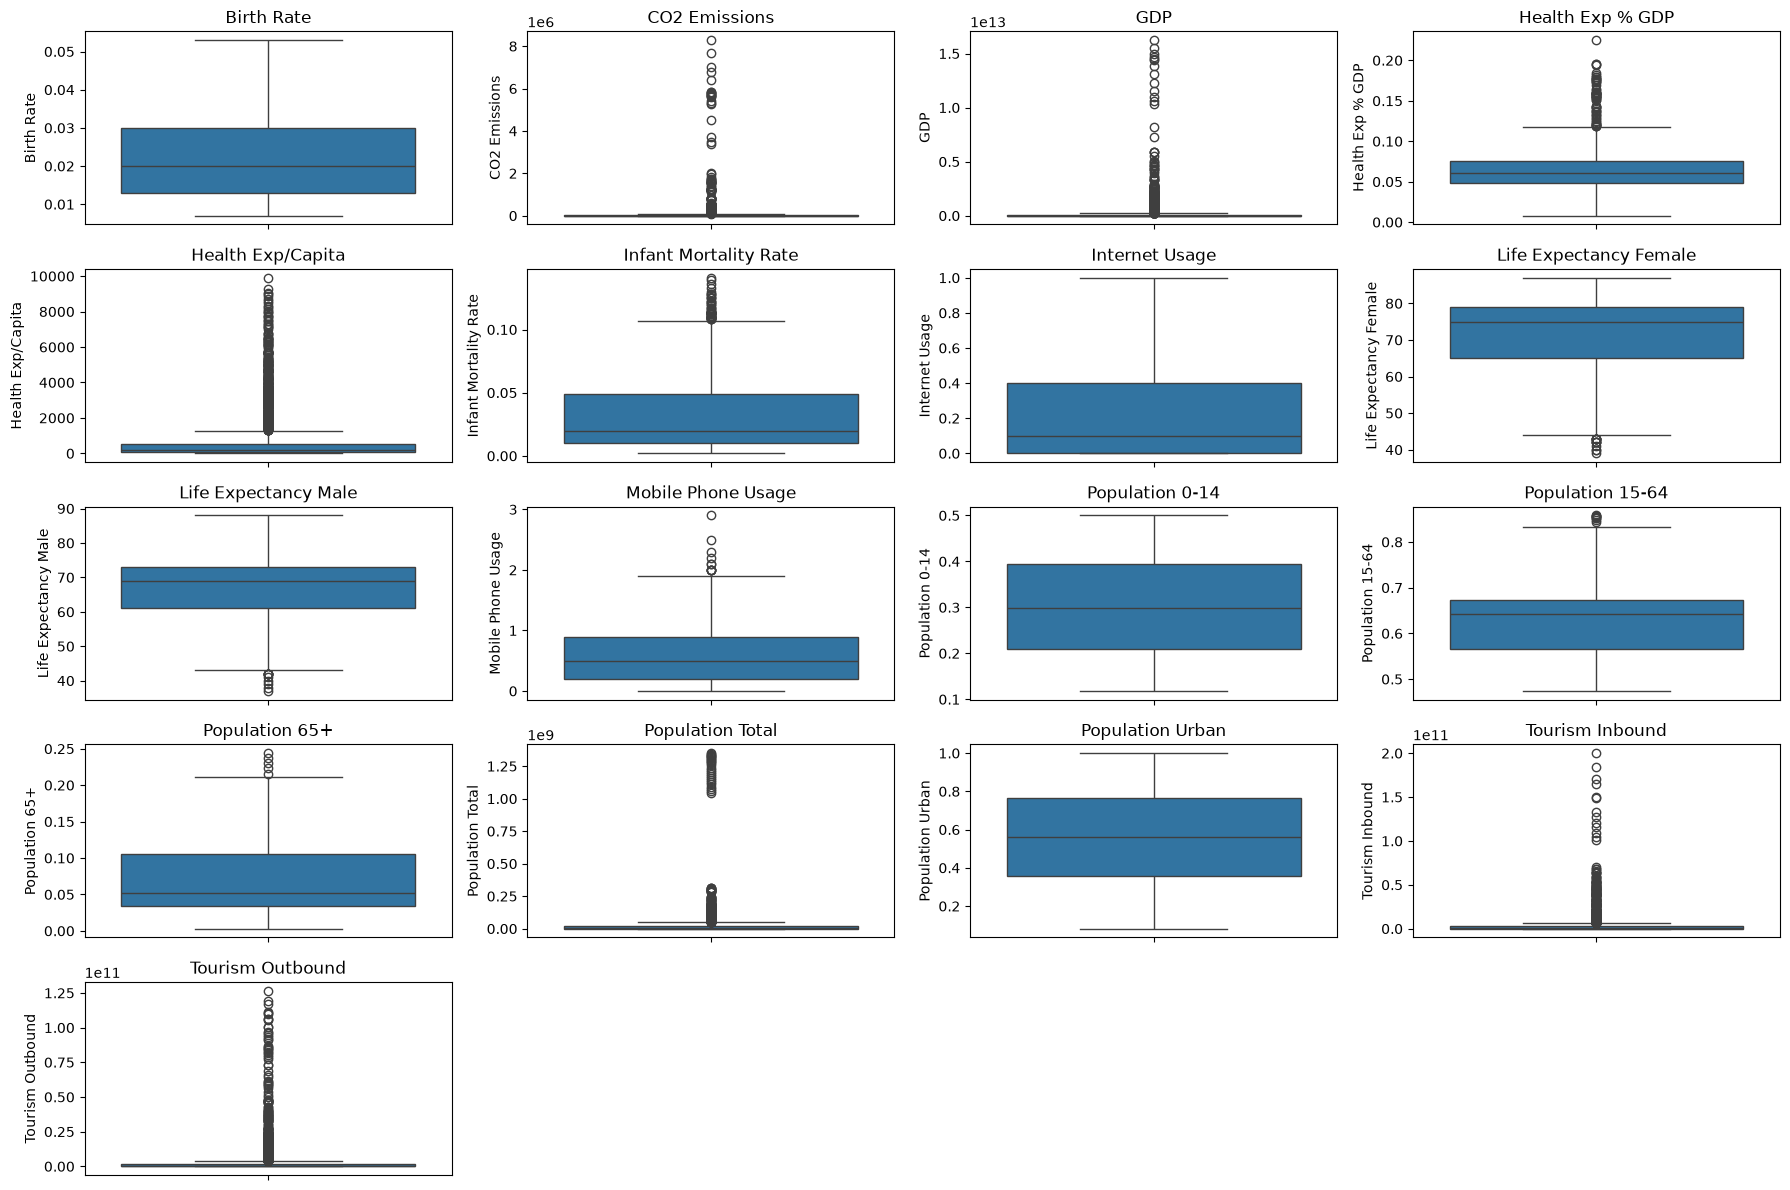

In [ ]:
plt.figure(figsize=(18, 12))

for i, col in enumerate(numerical_cols, 1):
    plt.subplot(5, 4, i)
    sns.boxplot(y=gdf[col])
    
    plt.title(col)

plt.tight_layout()
plt.show()

### Interpretation of Boxplot Analysis

The boxplots show that GDP, CO₂ Emissions, Population Total, Tourism Inbound, Tourism Outbound, and Health Exp/Capita have substantial upper outliers and strong right-skewness. These extreme values can disproportionately influence distance-based clustering.

Other variables have comparatively fewer or less severe outliers. The identified extreme observations should not be removed automatically, as they may represent genuine differences between countries.

### correlation analysis
To identify highly correlated/redundant variables before deciding the final feature set and applying transformations/scaling for clustering.

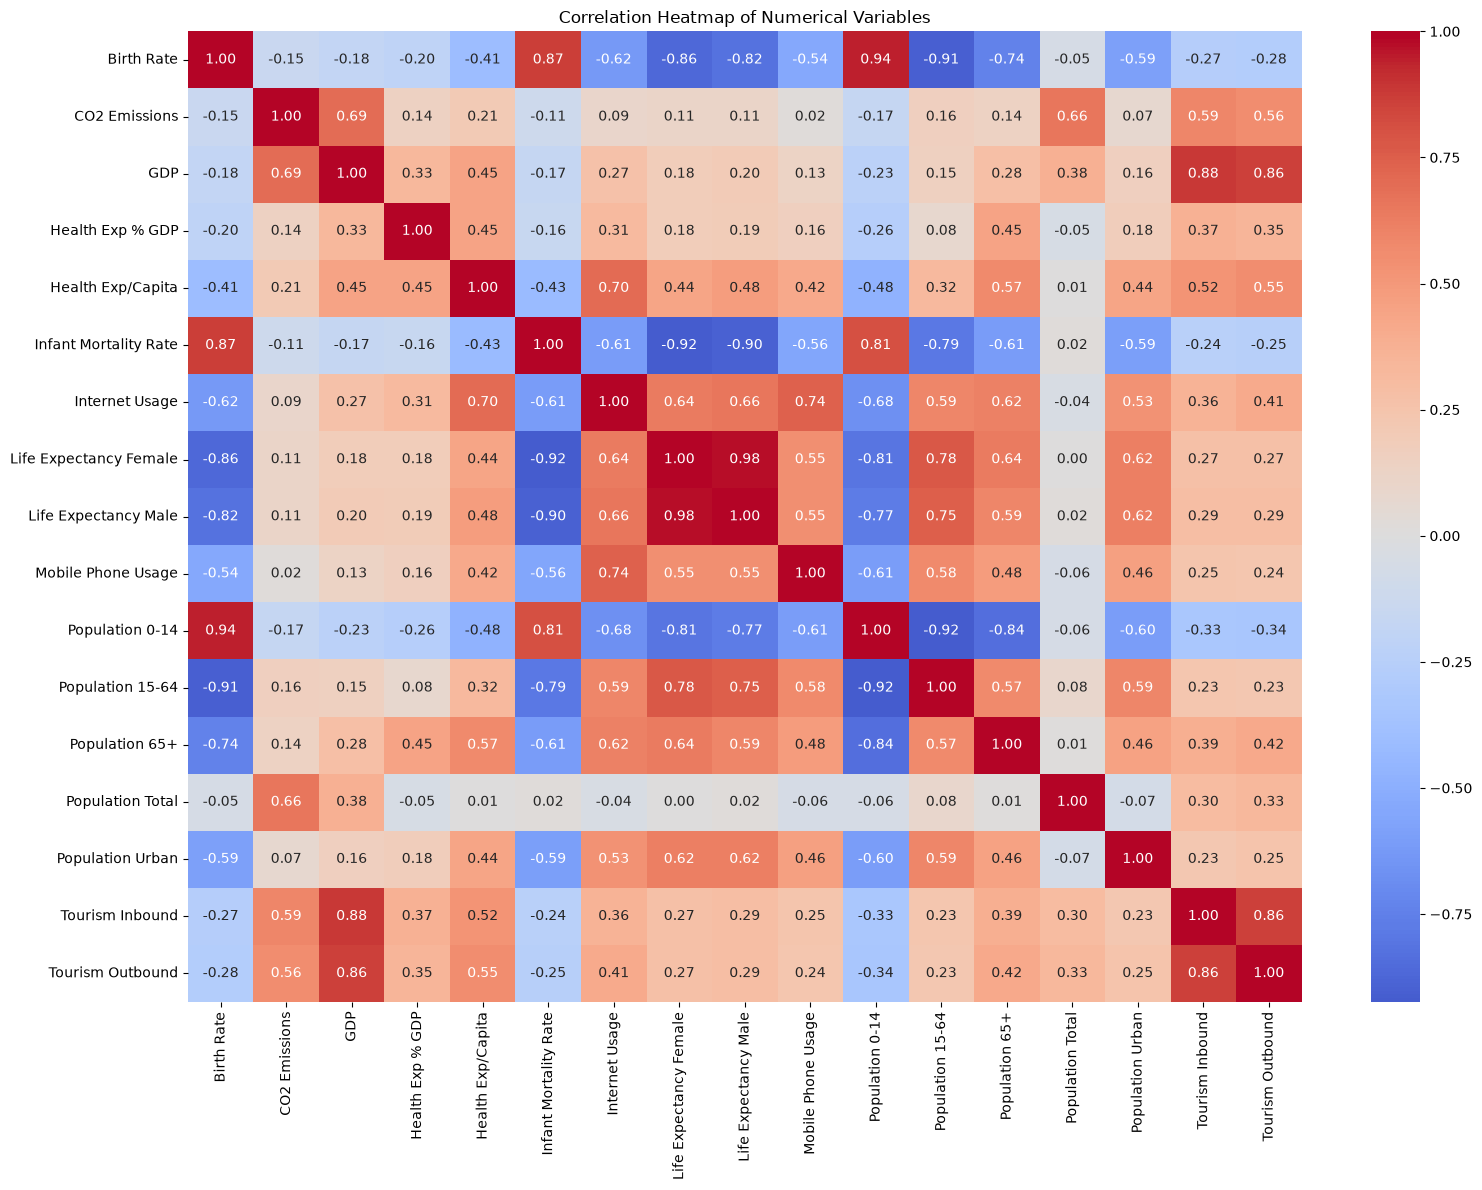

In [ ]:
correlation_matrix = gdf[numerical_cols].corr()

plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap of Numerical Variables")
plt.tight_layout()
plt.show()

### Interpretation of Correlation Analysis

- Several **strong correlations** are observed among the development indicators.
- **Life Expectancy Female and Life Expectancy Male** show a very strong positive correlation (**0.98**), indicating substantial redundancy.
- **GDP and Tourism Inbound** (**0.88**) and **GDP and Tourism Outbound** (**0.86**) are strongly positively correlated.
- **Birth Rate** has a strong positive correlation with **Population 0–14** (**0.94**) and strong negative correlations with **Population 15–64** (**−0.91**) and **Life Expectancy Female** (**−0.86**).
- **Infant Mortality Rate** is strongly negatively correlated with **Life Expectancy Female** (**−0.92**) and **Life Expectancy Male** (**−0.90**).
- **Population 0–14 and Population 15–64** also show a strong negative correlation (**−0.92**).
- These highly correlated variables may contain overlapping information and should be considered during **feature selection** to reduce redundancy before clustering.
- The correlation analysis will therefore guide **feature selection and subsequent clustering preparation**, along with skewness, outlier analysis, and scaling.

### Feature Transformation

The skewness and distribution analysis identified several numerical variables with strong right-skewness and extreme values.

Since clustering algorithms such as K-Means are distance-based, these extreme values can disproportionately influence cluster formation. Therefore, suitable transformations will be considered for strongly right-skewed variables.

For non-negative variables with substantial right-skewness, the `log1p()` transformation will be applied to reduce skewness and compress the effect of extreme values.
GDP                       9.809793

CO2 Emissions             9.768254

Population Total          8.788164

Tourism Inbound           7.638561

Tourism Outbound          5.757210

Health Exp/Capita         3.047889

After transformation, the skewness of the variables will be rechecked to assess the effectiveness of the transformation before proceeding to final feature selection and scaling.

In [ ]:
# Variables selected for log1p transformation

log_cols = [
    'GDP',
    'CO2 Emissions',
    'Population Total',
    'Tourism Inbound',
    'Tourism Outbound',
    'Health Exp/Capita'
]

# Apply log1p transformation
gdf[log_cols] = np.log1p(gdf[log_cols])

Check whether the transformation reduced skewness:

In [ ]:
# Check skewness after transformation

skewness_after = gdf[numerical_cols].skew().sort_values(ascending=False)

print("Skewness after transformation:")
print(skewness_after)

Skewness after transformation:
Health Exp % GDP          1.293975
Infant Mortality Rate     1.195218
Internet Usage            1.041279
Population 65+            1.040362
Birth Rate                0.706320
Mobile Phone Usage        0.617739
GDP                       0.251343
Health Exp/Capita         0.209499
CO2 Emissions             0.088705
Population 0-14           0.070722
Population Urban          0.012928
Tourism Outbound         -0.015155
Population 15-64         -0.260727
Tourism Inbound          -0.273627
Population Total         -0.371783
Life Expectancy Male     -0.760670
Life Expectancy Female   -0.958938
dtype: float64


### Interpretation of Skewness After Transformation

The `log1p()` transformation substantially reduced the strong right-skewness of the selected variables. Their skewness values are now close to zero, indicating much more balanced distributions.

This transformation has therefore reduced the influence of extreme values and improved the suitability of these variables for distance-based clustering. The remaining variables with moderate skewness will be retained for further analysis and feature selection.

### Recheck distributions after transformation

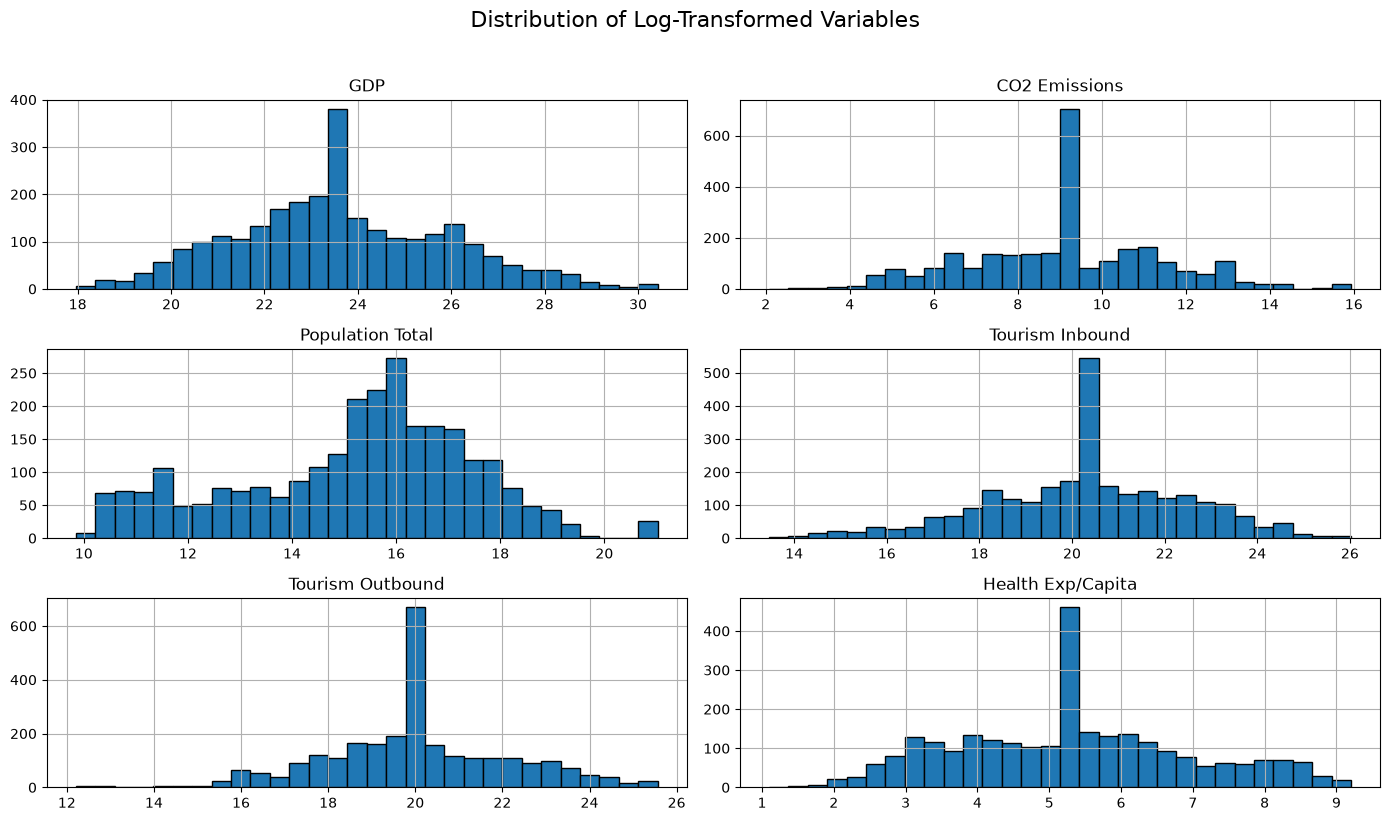

In [ ]:
# Recheck distributions of transformed variables

gdf[log_cols].hist(
    figsize=(14, 8),
    bins=30,
    edgecolor='black'
)

plt.suptitle(
    'Distribution of Log-Transformed Variables',
    fontsize=16,
    y=1.02
)

plt.tight_layout()
plt.show()

The log1p() transformation substantially reduced the skewness of the selected variables and produced more balanced distributions. No further transformation is required at this stage.

### Final Feature Selection

The next step is to identify highly correlated or redundant numerical variables based on the correlation analysis. Variables carrying substantially overlapping information will be reviewed before finalizing the feature set for clustering.

The selected features will then be scaled to ensure that differences in measurement units and magnitude do not disproportionately influence the clustering algorithms.

###  Identify highly correlated/redundant feature pairs

In [ ]:
# Identify highly correlated feature pairs

corr_matrix = gdf[numerical_cols].corr().abs()

high_corr = corr_matrix[
    (corr_matrix >= 0.80) & (corr_matrix < 1.0)
]

high_corr

,Birth Rate,CO2 Emissions,GDP,Health Exp % GDP,Health Exp/Capita,Infant Mortality Rate,Internet Usage,Life Expectancy Female,Life Expectancy Male,Mobile Phone Usage,Population 0-14,Population 15-64,Population 65+,Population Total,Population Urban,Tourism Inbound,Tourism Outbound
Birth Rate,NaN,NaN,NaN,NaN,NaN,0.866444,NaN,0.864448,0.821947,NaN,0.941822,0.906371,NaN,NaN,NaN,NaN,NaN
CO2 Emissions,NaN,NaN,0.831516,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
GDP,NaN,0.831516,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.803617,0.887327
Health Exp % GDP,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Health Exp/Capita,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Infant Mortality Rate,0.866444,NaN,NaN,NaN,NaN,NaN,NaN,0.922481,0.900726,NaN,0.808403,NaN,NaN,NaN,NaN,NaN,NaN
Internet Usage,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Life Expectancy Female,0.864448,NaN,NaN,NaN,NaN,0.922481,NaN,NaN,0.976893,NaN,0.810456,NaN,NaN,NaN,NaN,NaN,NaN
Life Expectancy Male,0.821947,NaN,NaN,NaN,NaN,0.900726,NaN,0.976893,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Mobile Phone Usage,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
high_corr_pairs = high_corr.stack().dropna()
print(high_corr_pairs)

#Convert the high-correlation matrix into feature-pair form and keep only the pairs that have an actual correlation value.

Birth Rate              Infant Mortality Rate     0.866444
                        Life Expectancy Female    0.864448
                        Life Expectancy Male      0.821947
                        Population 0-14           0.941822
                        Population 15-64          0.906371
CO2 Emissions           GDP                       0.831516
GDP                     CO2 Emissions             0.831516
                        Tourism Inbound           0.803617
                        Tourism Outbound          0.887327
Infant Mortality Rate   Birth Rate                0.866444
                        Life Expectancy Female    0.922481
                        Life Expectancy Male      0.900726
                        Population 0-14           0.808403
Life Expectancy Female  Birth Rate                0.864448
                        Infant Mortality Rate     0.922481
                        Life Expectancy Male      0.976893
                        Population 0-14           0.8104

### High-Correlation Feature Review

The correlation analysis identified several pairs of features with an absolute correlation of **0.80 or higher**. However, high correlation alone is not sufficient reason to remove a feature in an unsupervised clustering problem. The conceptual meaning of the variables was also considered.

#### Feature selected for removal

* **Life Expectancy Male vs Life Expectancy Female (0.977)**
  These two variables measure essentially the same underlying dimension—**life expectancy**—and therefore contain highly overlapping information. Retaining both could give excessive weight to this dimension during distance-based clustering.

  **Decision:** Remove **Life Expectancy Male** and retain **Life Expectancy Female**.

#### Highly correlated features retained

The other highly correlated pairs were retained because they represent **distinct aspects of population, health, economic activity, or development**, even though they are statistically correlated.

* **Birth Rate, Infant Mortality Rate and Population indicators**
  These variables are related to demographic and health conditions, but each represents a different development characteristic. Removing them solely because of correlation could result in loss of meaningful information.

* **GDP, CO2 Emissions, Tourism Inbound and Tourism Outbound**
  These variables are correlated with economic activity, but they represent different dimensions: **economic output, environmental impact, and international tourism activity**. Therefore, they are retained.

* **Population 0–14, Population 15–64 and Population 65+**
  These variables describe different **age-group structures** of the population. Although they are correlated, each provides information about a different demographic segment and may help distinguish countries in clustering.

### Final Decision

Therefore, correlation analysis was used as a **feature-review step rather than an automatic feature-removal rule**. After considering both statistical correlation and the conceptual meaning of the variables, **only Life Expectancy Male was removed**, while the other correlated features were retained because they provide distinct information relevant to country development.


In [ ]:
gdf.shape

(2704, 18)

In [ ]:
# Remove the redundant feature
gdf.drop(columns=['Life Expectancy Male'], inplace=True)

# Country is an identifier, not a clustering feature
final_features = [col for col in gdf.columns if col != 'Country']

print("Final features:")
print(final_features)

print("\nNumber of final features:", len(final_features))

Final features:
['Birth Rate', 'CO2 Emissions', 'GDP', 'Health Exp % GDP', 'Health Exp/Capita', 'Infant Mortality Rate', 'Internet Usage', 'Life Expectancy Female', 'Mobile Phone Usage', 'Population 0-14', 'Population 15-64', 'Population 65+', 'Population Total', 'Population Urban', 'Tourism Inbound', 'Tourism Outbound']

Number of final features: 16


In [ ]:
# Create the final feature dataframe
fgdf = gdf[final_features].copy()

print("Shape of final feature dataframe:", fgdf.shape)
fgdf.shape

Shape of final feature dataframe: (2704, 16)


(2704, 16)

### Final Feature Selection – Decision

At this stage, the dataset is ready for clustering preparation:

- **2,704 country-level observations**
- **16 final numerical features**
- `Country` is retained separately as an identifier and will not be used as a clustering feature.
- `Life Expectancy Male` has been removed due to its strong conceptual redundancy with `Life Expectancy Female`.
- Six highly skewed variables have already been **log1p transformed**.
- Missing values have been appropriately handled.
- **No further feature removal is required at this stage.**

The next step is to **standardize the 16 final numerical features** before applying clustering algorithms.

### Why Standardization is Required

The 16 selected features have different units, ranges, and magnitudes. Since clustering algorithms such as **K-Means and Hierarchical Clustering are distance-based**, variables with larger numerical values could disproportionately influence the clustering process.

Therefore, the features will be **standardized** so that each variable contributes more comparably to the distance calculations.

In [ ]:
# Create the scaler
scaler = StandardScaler()

# Standardize the final features
fgdf_scaled = scaler.fit_transform(fgdf)

print("Scaled data shape:", fgdf_scaled.shape)

Scaled data shape: (2704, 16)


### Conversion Back to DataFrame

The standardized data is returned as a NumPy array. Therefore, it is converted back into a DataFrame to retain the feature names and facilitate further analysis and clustering.

In [ ]:
# Convert scaled data back to a DataFrame
fgdf_scaled = pd.DataFrame(
    fgdf_scaled,
    columns=final_features,
    index=fgdf.index
)

### Checking Standardization

In [ ]:

print("Mean of scaled features:")
print(fgdf_scaled.mean().round(2))

print("\nStandard deviation of scaled features:")
print(fgdf_scaled.std().round(2))

Mean of scaled features:
Birth Rate               -0.0
CO2 Emissions            -0.0
GDP                       0.0
Health Exp % GDP         -0.0
Health Exp/Capita         0.0
Infant Mortality Rate    -0.0
Internet Usage           -0.0
Life Expectancy Female    0.0
Mobile Phone Usage        0.0
Population 0-14          -0.0
Population 15-64          0.0
Population 65+           -0.0
Population Total          0.0
Population Urban          0.0
Tourism Inbound           0.0
Tourism Outbound          0.0
dtype: float64

Standard deviation of scaled features:
Birth Rate                1.0
CO2 Emissions             1.0
GDP                       1.0
Health Exp % GDP          1.0
Health Exp/Capita         1.0
Infant Mortality Rate     1.0
Internet Usage            1.0
Life Expectancy Female    1.0
Mobile Phone Usage        1.0
Population 0-14           1.0
Population 15-64          1.0
Population 65+            1.0
Population Total          1.0
Population Urban          1.0
Tourism Inbound     

### Preserving the Final Feature Datasets

The final unscaled feature dataset and the standardized feature dataset are preserved separately.

- `fgdf_final` – final selected features before standardization, retained for interpretation and cluster profiling.
- `fgdf_scaled_final` – standardized features, used as input for clustering algorithms.

In [ ]:
# Preserve the final unscaled feature dataframe
fgdf_final = fgdf.copy()

# Preserve the final standardized feature dataframe
fgdf_scaled_final = fgdf_scaled.copy()

print("Final unscaled features:", fgdf_final.shape)
print("Final scaled features:", fgdf_scaled_final.shape)

Final unscaled features: (2704, 16)
Final scaled features: (2704, 16)


In [ ]:
# Save final datasets for future use
fgdf_final.to_csv("final_unscaled_features.csv", index=False)
fgdf_scaled_final.to_csv("final_scaled_features.csv", index=False)

### EDA Phase – Final Findings and Conclusion

The EDA and data-preparation phase is now complete.

- Data quality issues were identified and addressed.
- High-missing-value features were removed and remaining missing values were imputed.
- Distributions, skewness, outliers, and correlations were analysed.
- Highly skewed variables were appropriately transformed using `log1p()`.
- Redundant features were reviewed and `Life Expectancy Male` was removed.
- The final feature set contains **16 numerical features**.
- The features were standardized to ensure comparable contribution to distance-based clustering.
- Both the final unscaled and standardized feature datasets have been preserved.

The dataset is now **clean, validated, feature-ready, and standardized for clustering model development**.

### Next Phase

**Clustering Model Building → K-Means → Hierarchical Clustering → DBSCAN/other suitable methods → Evaluation → Comparative Analysis → Cluster Profiling → Streamlit Deployment**

In [ ]:
# 🤖 Clustering Model Building

print("""The dataset is now cleaned, transformed, feature-selected, and standardized.

Since this is an unsupervised learning problem, there is no target variable. Therefore, different clustering algorithms will be applied to identify natural groups of countries based on their development characteristics.

The following clustering algorithms will be evaluated:

1. K-Means Clustering
2. Hierarchical (Agglomerative) Clustering
3. DBSCAN

The models will be compared using clustering evaluation metrics such as Silhouette Score, Davies-Bouldin Index, and Calinski-Harabasz Score.""")

The dataset is now cleaned, transformed, feature-selected, and standardized.

Since this is an unsupervised learning problem, there is no target variable. Therefore, different clustering algorithms will be applied to identify natural groups of countries based on their development characteristics.

The following clustering algorithms will be evaluated:

1. K-Means Clustering
2. Hierarchical (Agglomerative) Clustering
3. DBSCAN

The models will be compared using clustering evaluation metrics such as Silhouette Score, Davies-Bouldin Index, and Calinski-Harabasz Score.


In [ ]:
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

In [ ]:
fgdf_scaled_final

,Birth Rate,CO2 Emissions,GDP,Health Exp % GDP,Health Exp/Capita,Infant Mortality Rate,Internet Usage,Life Expectancy Female,Mobile Phone Usage,Population 0-14,Population 15-64,Population 65+,Population Total,Population Urban,Tourism Inbound,Tourism Outbound
0,-0.233864,1.011815,0.482111,-1.162045,-0.735597,0.084186,-0.908914,-0.033671,-1.246165,0.384182,-0.090043,-0.683981,0.898341,0.147449,-0.868805,-0.452653
1,2.469335,0.025108,-0.306041,-1.202383,-1.333398,3.355575,-0.908914,-2.326553,-1.246165,1.696192,-1.882290,-0.976654,0.538824,-0.976530,-1.382507,-0.585460
2,1.838589,-0.763374,-0.901219,-0.839336,-1.555819,2.033099,-0.908914,-1.371185,-1.246165,1.480788,-1.613453,-0.893033,0.235301,-0.735385,-1.000276,-1.095392
3,0.396882,-0.331477,-0.506458,-0.677982,-0.172005,0.780226,-0.908914,-1.848869,-1.028797,0.785618,-0.567976,-0.893033,-0.365590,-0.126393,-0.494742,-0.414753
4,2.108909,-0.958893,-0.856609,-0.516628,-1.683079,2.241911,-0.908914,-1.848869,-1.246165,1.617863,-1.792677,-0.913938,0.459348,-1.573260,-1.565273,-1.338478
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2699,-0.233864,-0.024752,-0.085325,-0.113243,-0.026493,-0.403042,-0.515114,0.348476,-0.159328,-0.031941,0.260938,-0.412213,-2.108661,1.422654,0.024082,-0.043501
2700,-0.864611,-0.024752,2.985570,4.646701,2.318119,-0.890270,2.241482,0.921696,0.927509,-1.045322,0.626855,1.343825,1.899295,1.013934,2.676270,2.633771
2701,-0.684397,-0.024752,0.441912,1.016235,1.143614,-0.751062,1.060084,0.826160,2.014346,-0.810335,0.208665,1.427446,-0.077498,1.573880,0.571934,0.343322
2702,-0.233864,-0.024752,1.335380,-0.718321,0.659345,-0.646656,1.060084,0.635086,0.927509,-0.144539,0.402825,-0.244971,0.873344,1.332735,0.151413,0.883984


In [ ]:
## K-Means Clustering
#K-Means clustering partitions countries into K clusters by assigning each country to the nearest cluster centroid.
#The optimal number of clusters will first be investigated using the Elbow Method.

In [ ]:
inertia = []

K_range = range(2, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(fgdf_scaled_final)
    inertia.append(kmeans.inertia_)

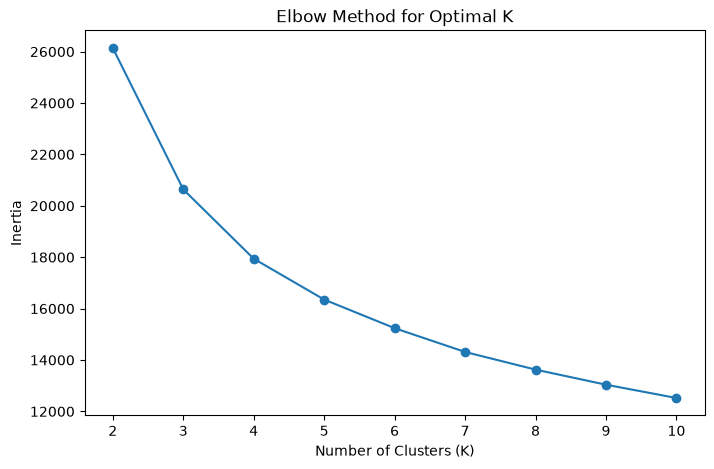

In [ ]:
plt.figure(figsize=(8,5))
plt.plot(K_range, inertia, marker='o')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.title('Elbow Method for Optimal K')
plt.show()

In [ ]:
#silhoute scores
silhouette_scores = []

for k in range(2, 11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(fgdf_scaled_final)

    score = silhouette_score(
        fgdf_scaled_final,
        labels
    )

    silhouette_scores.append(score)

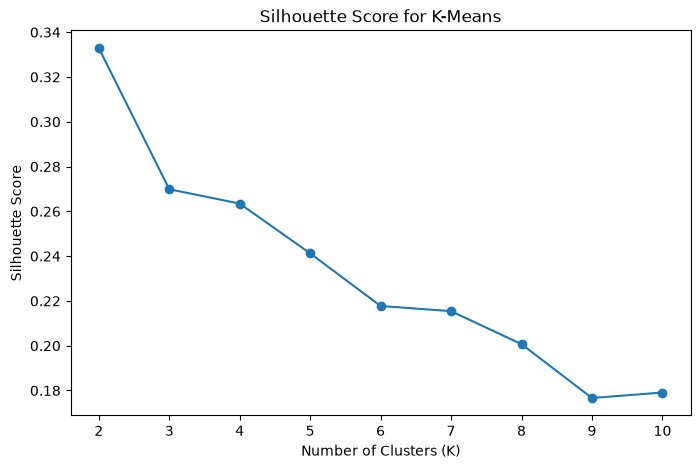

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(
    range(2,11),
    silhouette_scores,
    marker='o'
)
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score for K-Means')
plt.show()

In [ ]:
best_k = range(2, 11)[np.argmax(silhouette_scores)]

print("Best K based on Silhouette Score:", best_k)
print("Best Silhouette Score:", max(silhouette_scores))

Best K based on Silhouette Score: 2
Best Silhouette Score: 0.3329392911511963


In [ ]:
kmeans_final = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans_final.fit_predict(
    fgdf_scaled_final
)

In [ ]:
pd.Series(kmeans_labels).value_counts().sort_index()

0    1095
1    1609
Name: count, dtype: int64

In [ ]:
# add k means cluster to country data
kmeans_result = gdf[['Country']].copy()

kmeans_result['KMeans_Cluster'] = kmeans_labels

kmeans_result.head()

,Country,KMeans_Cluster
0,Algeria,0
1,Angola,0
2,Benin,0
3,Botswana,0
4,Burkina Faso,0


In [ ]:
kmeans_silhouette = silhouette_score(
    fgdf_scaled_final,
    kmeans_labels
)

kmeans_db = davies_bouldin_score(
    fgdf_scaled_final,
    kmeans_labels
)

kmeans_ch = calinski_harabasz_score(
    fgdf_scaled_final,
    kmeans_labels
)

print("K-Means Evaluation:")
print("Silhouette Score:", round(kmeans_silhouette, 4))
print("Davies-Bouldin Index:", round(kmeans_db, 4))
print("Calinski-Harabasz Score:", round(kmeans_ch, 4))

K-Means Evaluation:
Silhouette Score: 0.3329
Davies-Bouldin Index: 1.15
Calinski-Harabasz Score: 1769.943


In [ ]:
## Hierarchical Clustering

#Agglomerative Hierarchical Clustering starts by treating each observation as an individual cluster and progressively merges similar observations until the desired number of clusters is obtained.

#This model provides an alternative clustering structure to K-Means.

In [ ]:
hierarchical = AgglomerativeClustering(
    n_clusters=best_k,
    linkage='ward'
)

hierarchical_labels = hierarchical.fit_predict(
    fgdf_scaled_final
)

In [ ]:
pd.Series(hierarchical_labels).value_counts().sort_index()

0    2014
1     690
Name: count, dtype: int64

In [ ]:
hier_silhouette = silhouette_score(
    fgdf_scaled_final,
    hierarchical_labels
)

hier_db = davies_bouldin_score(
    fgdf_scaled_final,
    hierarchical_labels
)

hier_ch = calinski_harabasz_score(
    fgdf_scaled_final,
    hierarchical_labels
)

print("Hierarchical Clustering Evaluation")
print("Silhouette Score:", round(hier_silhouette, 4))
print("Davies-Bouldin Index:", round(hier_db, 4))
print("Calinski-Harabasz Score:", round(hier_ch, 4))

Hierarchical Clustering Evaluation
Silhouette Score: 0.2981
Davies-Bouldin Index: 1.0905
Calinski-Harabasz Score: 1265.3114


In [ ]:
from scipy.cluster.hierarchy import dendrogram, linkage

In [ ]:
linked = linkage(
    fgdf_scaled_final,
    method='ward'
)

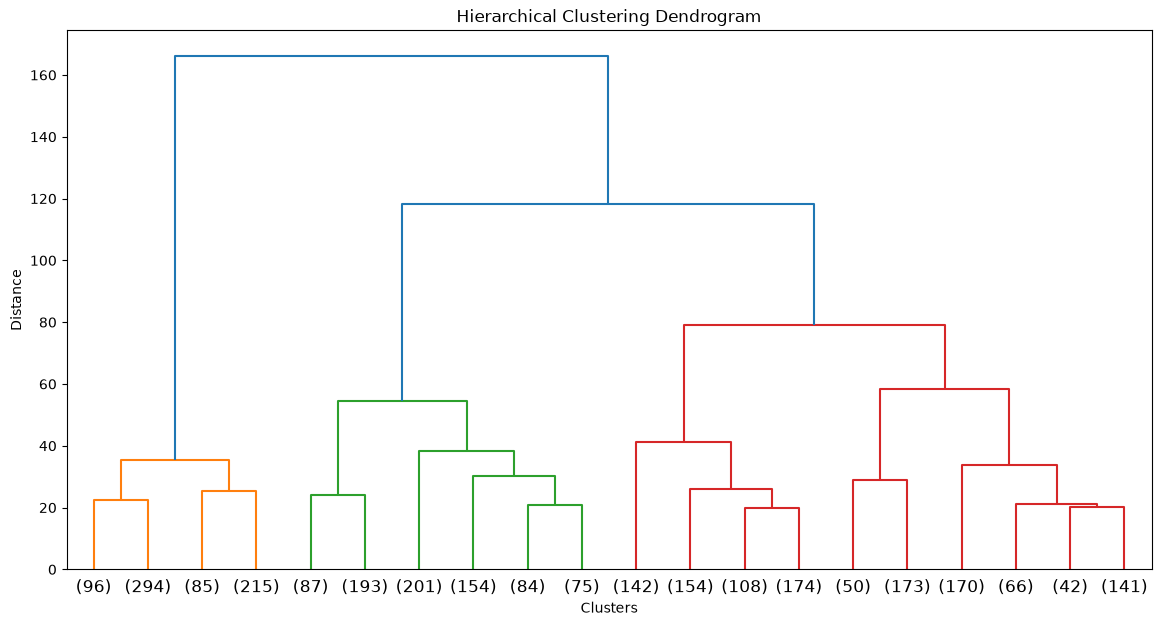

In [ ]:
plt.figure(figsize=(14,7))

dendrogram(
    linked,
    truncate_mode='lastp',
    p=20
)

plt.title('Hierarchical Clustering Dendrogram')
plt.xlabel('Clusters')
plt.ylabel('Distance')

plt.show()

In [ ]:
truncate_mode='lastp'

In [ ]:
## DBSCAN Clustering

##DBSCAN is a density-based clustering algorithm that identifies groups based on the density of observations.

##Unlike K-Means and Hierarchical Clustering, DBSCAN does not require the number of clusters to be specified in advance. It can also identify observations that do not belong to any dense cluster as noise.

In [ ]:
dbscan = DBSCAN(
    eps=1.5,
    min_samples=10
)

dbscan_labels = dbscan.fit_predict(
    fgdf_scaled_final
)

In [ ]:
pd.Series(dbscan_labels).value_counts().sort_index()

-1      396
 0     1954
 1       13
 2       24
 3       12
 4       13
 5       23
 6       22
 7       11
 8       13
 9       10
 10      11
 11      11
 12       9
 13      26
 14      10
 15      11
 16      13
 17      11
 18      11
 19       9
 20      12
 21      10
 22      13
 23      11
 24       9
 25      10
 26       9
 27       7
 28      10
Name: count, dtype: int64

In [ ]:
n_clusters_dbscan = len(
    set(dbscan_labels)
) - (1 if -1 in dbscan_labels else 0)

n_noise = list(dbscan_labels).count(-1)

print("Number of clusters:", n_clusters_dbscan)
print("Number of noise points:", n_noise)

Number of clusters: 29
Number of noise points: 396


In [ ]:
if n_clusters_dbscan >= 2:

    dbscan_silhouette = silhouette_score(
        fgdf_scaled_final,
        dbscan_labels
    )

    dbscan_db = davies_bouldin_score(
        fgdf_scaled_final,
        dbscan_labels
    )

    dbscan_ch = calinski_harabasz_score(
        fgdf_scaled_final,
        dbscan_labels
    )

    print("Silhouette Score:", round(dbscan_silhouette, 4))
    print("Davies-Bouldin Index:", round(dbscan_db, 4))
    print("Calinski-Harabasz Score:", round(dbscan_ch, 4))

else:

    print("DBSCAN did not produce enough clusters for evaluation.")

Silhouette Score: -0.3186
Davies-Bouldin Index: 1.6934
Calinski-Harabasz Score: 17.9342


In [ ]:
eps_values = [0.5, 0.75, 1.0, 1.25, 1.5, 1.75, 2.0]

dbscan_results = []

for eps in eps_values:

    model = DBSCAN(
        eps=eps,
        min_samples=10
    )

    labels = model.fit_predict(
        fgdf_scaled_final
    )

    n_clusters = len(set(labels)) - (
        1 if -1 in labels else 0
    )

    noise = list(labels).count(-1)

    if n_clusters >= 2:

        score = silhouette_score(
            fgdf_scaled_final,
            labels
        )

    else:

        score = np.nan

    dbscan_results.append(
        [eps, n_clusters, noise, score]
    )

In [ ]:
dbscan_results_df = pd.DataFrame(
    dbscan_results,
    columns=[
        'eps',
        'clusters',
        'noise_points',
        'silhouette_score'
    ]
)

dbscan_results_df

,eps,clusters,noise_points,silhouette_score
0,0.50,5,2645,-0.325087
1,0.75,10,2561,-0.406107
2,1.00,37,1970,-0.312633
3,1.25,42,1135,-0.171301
4,1.50,29,396,-0.318607
5,1.75,11,126,-0.250503
6,2.00,4,50,-0.056712


In [ ]:
comparison = pd.DataFrame({

    'Model': [
        'K-Means',
        'Hierarchical',
        'DBSCAN'
    ],

    'Silhouette Score': [
        kmeans_silhouette,
        hier_silhouette,
        dbscan_silhouette if n_clusters_dbscan >= 2 else np.nan
    ],

    'Davies-Bouldin Index': [
        kmeans_db,
        hier_db,
        dbscan_db if n_clusters_dbscan >= 2 else np.nan
    ],

    'Calinski-Harabasz Score': [
        kmeans_ch,
        hier_ch,
        dbscan_ch if n_clusters_dbscan >= 2 else np.nan
    ]
})

comparison

,Model,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Score
0,K-Means,0.332939,1.150049,1769.943015
1,Hierarchical,0.298068,1.090544,1265.311392
2,DBSCAN,-0.318607,1.693390,17.934182


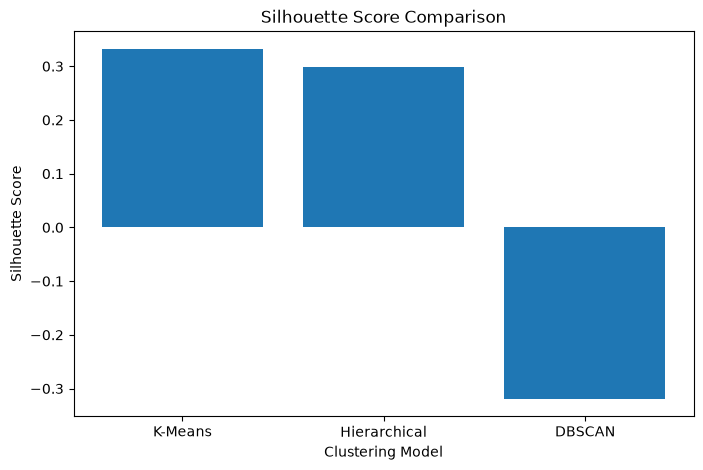

In [ ]:
plt.figure(figsize=(8,5))

plt.bar(comparison['Model'], comparison['Silhouette Score'])

plt.xlabel('Clustering Model')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score Comparison')

plt.show()

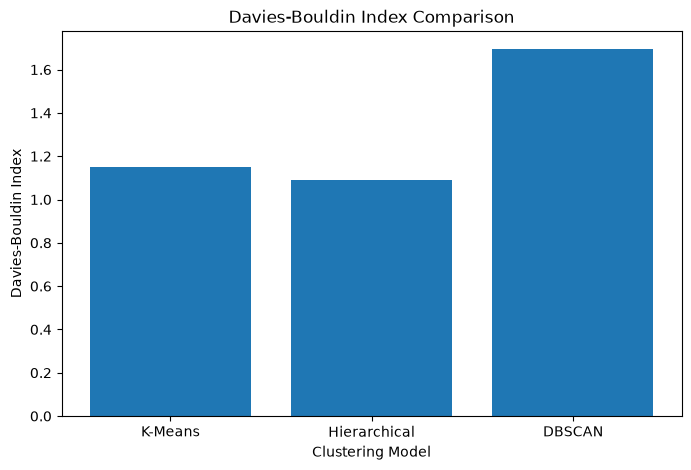

In [ ]:
plt.figure(figsize=(8,5))

plt.bar(comparison['Model'], comparison['Davies-Bouldin Index'])

plt.xlabel('Clustering Model')
plt.ylabel('Davies-Bouldin Index')
plt.title('Davies-Bouldin Index Comparison')

plt.show()

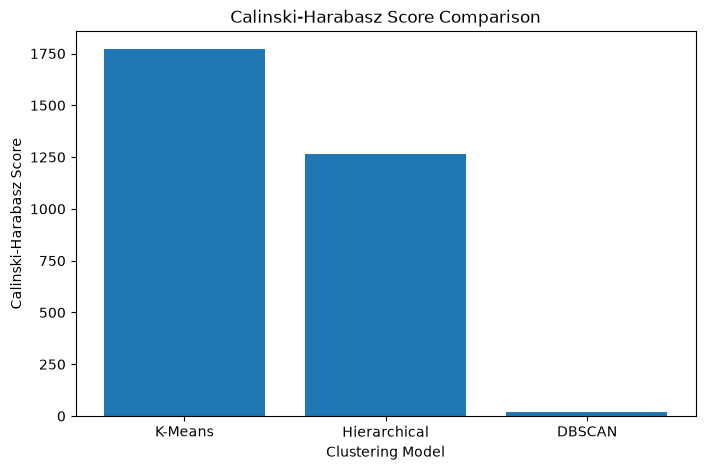

In [ ]:
plt.figure(figsize=(8,5))

plt.bar(comparison['Model'], comparison['Calinski-Harabasz Score'])

plt.xlabel('Clustering Model')
plt.ylabel('Calinski-Harabasz Score')
plt.title('Calinski-Harabasz Score Comparison')

plt.show()

In [ ]:
from sklearn.decomposition import PCA

In [ ]:
pca = PCA(n_components=2)

pca_data = pca.fit_transform(
    fgdf_scaled_final
)

pca_df = pd.DataFrame(
    pca_data,
    columns=['PC1', 'PC2']
)

pca_df['Cluster'] = kmeans_labels

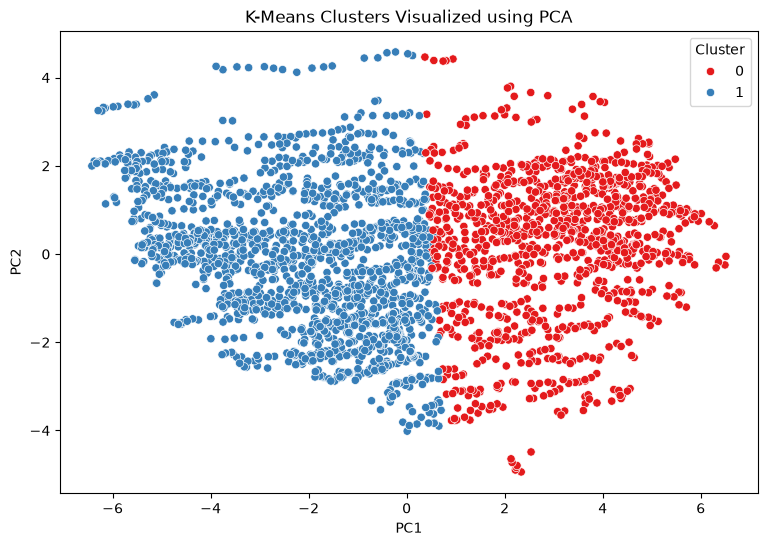

In [ ]:
plt.figure(figsize=(9,6))

sns.scatterplot(
    data=pca_df,
    x='PC1',
    y='PC2',
    hue='Cluster',
    palette='Set1'
)

plt.title('K-Means Clusters Visualized using PCA')
plt.show()

In [ ]:
profile_df = fgdf_final.copy()

profile_df['Cluster'] = kmeans_labels

cluster_profile = profile_df.groupby(
    'Cluster'
).mean()

cluster_profile

,Birth Rate,CO2 Emissions,GDP,Health Exp % GDP,Health Exp/Capita,Infant Mortality Rate,Internet Usage,Life Expectancy Female,Mobile Phone Usage,Population 0-14,Population 15-64,Population 65+,Population Total,Population Urban,Tourism Inbound,Tourism Outbound
Cluster,,,,,,,,,,,,,,,,
0,0.033299,7.800686,22.173545,0.058984,3.951519,0.057945,0.040457,61.712329,0.243562,0.403090,0.559862,0.036905,15.364642,0.369529,18.646528,18.601168
1,0.015311,9.996096,24.622227,0.067089,6.236332,0.013639,0.360348,77.912989,0.797700,0.234484,0.669378,0.095410,15.113750,0.694539,21.422786,21.001407


In [ ]:
cluster_profile_scaled = fgdf_scaled_final.copy()

cluster_profile_scaled['Cluster'] = kmeans_labels

cluster_profile_scaled = cluster_profile_scaled.groupby(
    'Cluster'
).mean()

cluster_profile_scaled

,Birth Rate,CO2 Emissions,GDP,Health Exp % GDP,Health Exp/Capita,Infant Mortality Rate,Internet Usage,Life Expectancy Female,Mobile Phone Usage,Population 0-14,Population 15-64,Population 65+,Population Total,Population Urban,Tourism Inbound,Tourism Outbound
Cluster,,,,,,,,,,,,,,,,
0,0.964431,-0.580433,-0.640851,-0.194547,-0.833264,0.917528,-0.749596,-0.920985,-0.716741,0.982321,-0.973297,-0.727777,0.065196,-0.790445,-0.772460,-0.679658
1,-0.656341,0.395012,0.436129,0.132398,0.567075,-0.624421,0.510135,0.626773,0.487776,-0.668516,0.662375,0.495286,-0.044369,0.537935,0.525695,0.462539


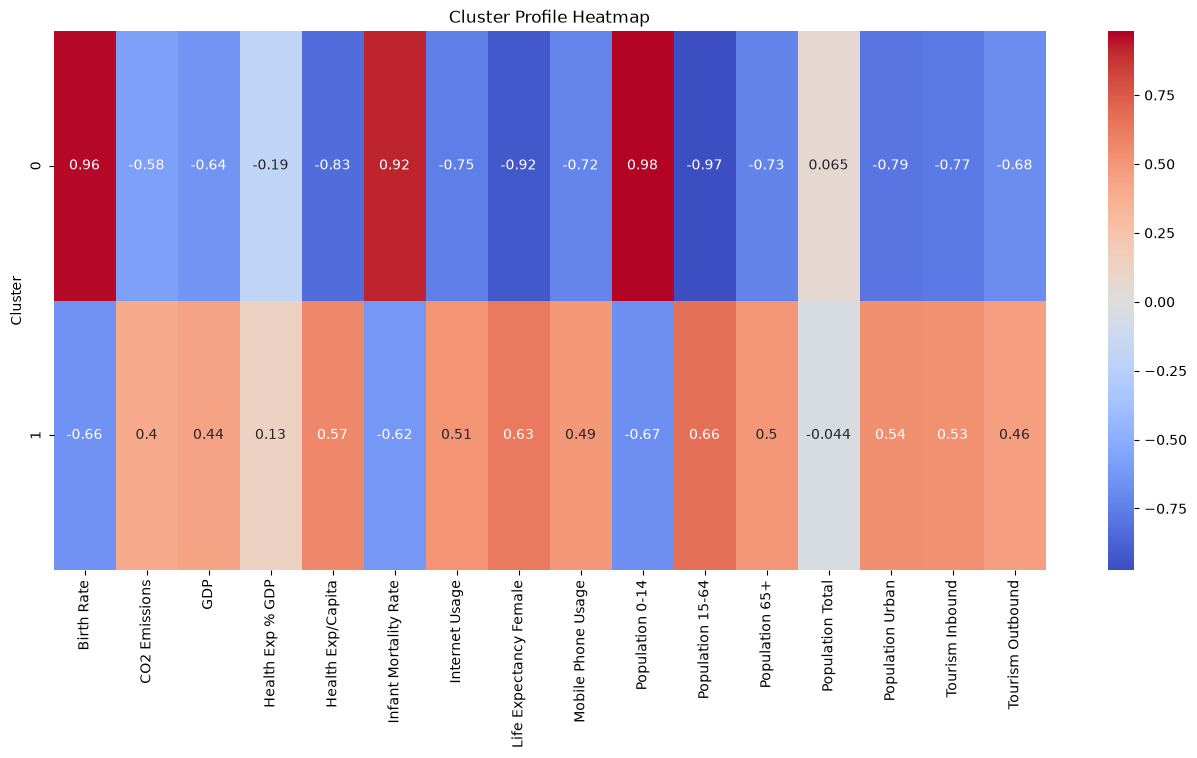

In [ ]:
plt.figure(figsize=(16,7))

sns.heatmap(
    cluster_profile_scaled,
    annot=True,
    cmap='coolwarm',
    center=0
)

plt.title('Cluster Profile Heatmap')

plt.show()

In [ ]:
country_clusters = gdf[
    ['Country']
].copy()

country_clusters['Cluster'] = kmeans_labels

country_clusters.sort_values(
    'Cluster'
).head(30)

,Country,Cluster
8,Chad,0
7,Central African Republic,0
6,Cameroon,0
5,Burundi,0
4,Burkina Faso,0
3,Botswana,0
2,Benin,0
1,Angola,0
0,Algeria,0
1099,Cambodia,0


In [ ]:
country_clusters[
    country_clusters['Cluster'] == 0
]

,Country,Cluster
0,Algeria,0
1,Angola,0
2,Benin,0
3,Botswana,0
4,Burkina Faso,0
...,...,...
2657,Tonga,0
2658,Vanuatu,0
2664,Belize,0
2682,Guyana,0


In [ ]:
country_clustering_data = pd.concat(
    [
        gdf[["Country"]].reset_index(drop=True),
        fgdf_final.reset_index(drop=True)
    ],
    axis=1
)

if len(country_clustering_data) != len(kmeans_labels):
    raise ValueError("Country rows and K-Means labels do not match.")

country_clustering_data["KMeans_Cluster"] = kmeans_labels
country_clustering_data.to_csv("country_clustering_data.csv", index=False)

print(
    f"Saved {len(country_clustering_data)} country records to "
    "country_clustering_data.csv"
)

Saved 2704 country records to country_clustering_data.csv
